**NAME: HIMANI DALVI**



**ROLL NO.: 07**


**BATCH: B3-B1**


**SI-PROJECT**

In [134]:
#Video Game Sales Analysis#

In [135]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [136]:
#PR1 - WEB SCRAPING (collecting video game data from a website)

In [137]:
import requests
from bs4 import BeautifulSoup

url = "https://en.wikipedia.org/wiki/List_of_best-selling_video_games"
headers = {"User-Agent": "Mozilla/5.0"}
response = requests.get(url, headers=headers)
print("Status code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")
print("Page title:", soup.title.text)
print("Heading:", soup.find("h1").text)

Status code: 200
Page title: List of best-selling video games - Wikipedia
Heading: List of best-selling video games


In [138]:
#Extract the best-selling games table
table = soup.find("table", class_="wikitable")
header = [th.get_text(strip=True) for th in table.find("tr").find_all("th")]
print(header)

n = len(header) - 1     # all columns except Rank
games = []

for row in table.find_all("tr")[1:]:
    cols = [c.get_text(strip=True) for c in row.find_all(["th", "td"])]
    if len(cols) >= n:
        games.append(cols[-n:])     # tied games have no Rank cell, so take the last n cells

scraped = pd.DataFrame(games, columns=header[1:])
print("Games scraped:", len(scraped))

['Rank', 'Title', 'Sales(millions)', 'Series', 'Platform(s)', 'Releaseyear', 'Developer(s)', 'Publisher(s)', 'Ref.']
Games scraped: 51


In [139]:
#Clean the scraped data and save to CSV
scraped = scraped.rename(columns={header[1]: "Title", header[2]: "Sales"})
scraped["Sales"] = scraped["Sales"].str.replace(r"\[.*?\]", "", regex=True)   # remove [a] notes
scraped["Sales"] = pd.to_numeric(scraped["Sales"], errors="coerce")
scraped = scraped.dropna(subset=["Sales"])

scraped.to_csv("best_selling_games.csv", index=False)
print(scraped[["Title", "Sales"]].head(10))
print("Average sales of these top games (millions):", scraped["Sales"].mean())

                         Title   Sales
0                       Tetris  520.00
1                    Minecraft  425.00
2           Grand Theft Auto V  230.00
3        Red Dead Redemption 2   87.00
4                Wii Sports[b]   82.90
5          Mario Kart 8/Deluxe   79.99
6          PUBG: Battlegrounds   75.00
7                     Terraria   70.00
8  The Elder Scrolls V: Skyrim   65.00
9     The Witcher 3: Wild Hunt   65.00
Average sales of these top games (millions): 61.88627450980392


In [140]:
#LOAD DATASET (Kaggle: Video Game Sales, vgsales.csv)

In [141]:
df = pd.read_csv("vgsales.csv")
print(df.shape)
df.head()

(16598, 11)


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [142]:
#PREPROCESSING

In [143]:
print(df.columns)

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='object')


In [144]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [145]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64


In [146]:
#CLEANING

In [147]:
df = df.dropna()

In [148]:
df["Year"] = df["Year"].astype(int)
df = df.drop_duplicates()

In [149]:
print("Clean data shape:", df.shape)
print("Missing values left:", df.isnull().sum().sum())

Clean data shape: (16291, 11)
Missing values left: 0


In [150]:
#summary

In [151]:
print("Total games:", len(df))
print("Numerical columns: Year, NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales")
print("Categorical columns: Platform, Genre, Publisher")
print()
print(df["Genre"].value_counts())

Total games: 16291
Numerical columns: Year, NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales
Categorical columns: Platform, Genre, Publisher

Genre
Action          3251
Sports          2304
Misc            1686
Role-Playing    1470
Shooter         1282
Adventure       1274
Racing          1225
Platform         875
Simulation       848
Fighting         836
Strategy         670
Puzzle           570
Name: count, dtype: int64


In [152]:
#PR2

In [153]:
#Global Sales statistics

In [154]:
g = df["Global_Sales"]
print("Mean=", g.mean())
print("Median=", g.median())
print("Mode=", g.mode()[0])
print("Variance=", g.var())
print("Std Dev=", g.std())
print("Range=", g.max() - g.min())
print("IQR=", g.quantile(0.75) - g.quantile(0.25))

Mean= 0.5409103185808114
Median= 0.17
Mode= 0.02
Variance= 2.456568802945086
Std Dev= 1.5673445067837146
Range= 82.72999999999999
IQR= 0.42


In [155]:
df[["Year", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]].describe()

,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000
mean,2006.405561,0.265647,0.147731,0.078833,0.048426,0.540910
std,5.832412,0.822432,0.509303,0.311879,0.190083,1.567345
min,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,2010.000000,0.240000,0.110000,0.040000,0.040000,0.480000
max,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [156]:
#Quartiles, min, max and skewness
Q1 = g.quantile(0.25)
Q2 = g.quantile(0.50)
Q3 = g.quantile(0.75)
print("Q1 =", Q1, " Q2 =", Q2, " Q3 =", Q3)
print("Min =", g.min(), " Max =", g.max())
print("Skewness =", g.skew())

Q1 = 0.06  Q2 = 0.17  Q3 = 0.48
Min = 0.01  Max = 82.74
Skewness = 17.30431167518343


In [157]:
#Genre-wise average sales

In [158]:
print(df.groupby("Genre")["Global_Sales"].mean().sort_values(ascending=False))

Genre
Platform        0.947577
Shooter         0.800468
Role-Playing    0.628456
Racing          0.593273
Sports          0.568247
Fighting        0.531160
Action          0.529942
Misc            0.468488
Simulation      0.459882
Puzzle          0.424930
Strategy        0.258612
Adventure       0.184137
Name: Global_Sales, dtype: float64


In [159]:
#Histogram of Global Sales

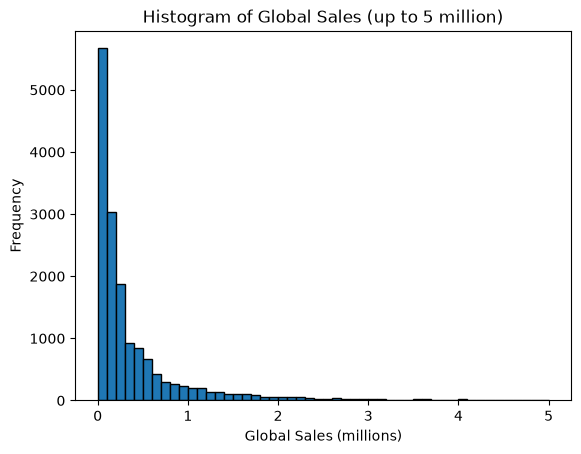

In [160]:
plt.hist(df["Global_Sales"], bins=50, edgecolor="black", range=(0, 5))
plt.title("Histogram of Global Sales (up to 5 million)")
plt.xlabel("Global Sales (millions)")
plt.ylabel("Frequency")
plt.show()

In [161]:
#Boxplot of Sales by Genre

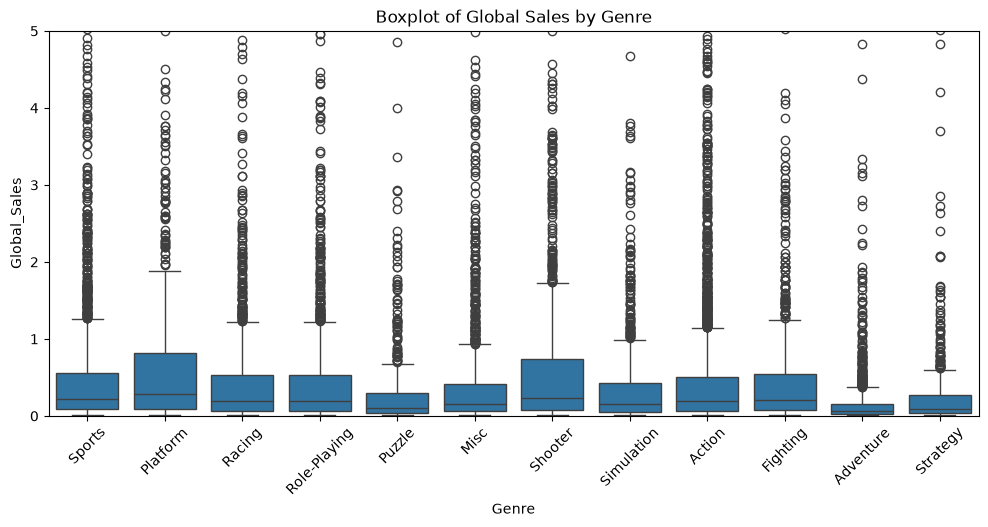

In [162]:
plt.figure(figsize=(12, 5))
sns.boxplot(x="Genre", y="Global_Sales", data=df)
plt.ylim(0, 5)
plt.xticks(rotation=45)
plt.title("Boxplot of Global Sales by Genre")
plt.show()

In [163]:
#Top 10 Games by Sales

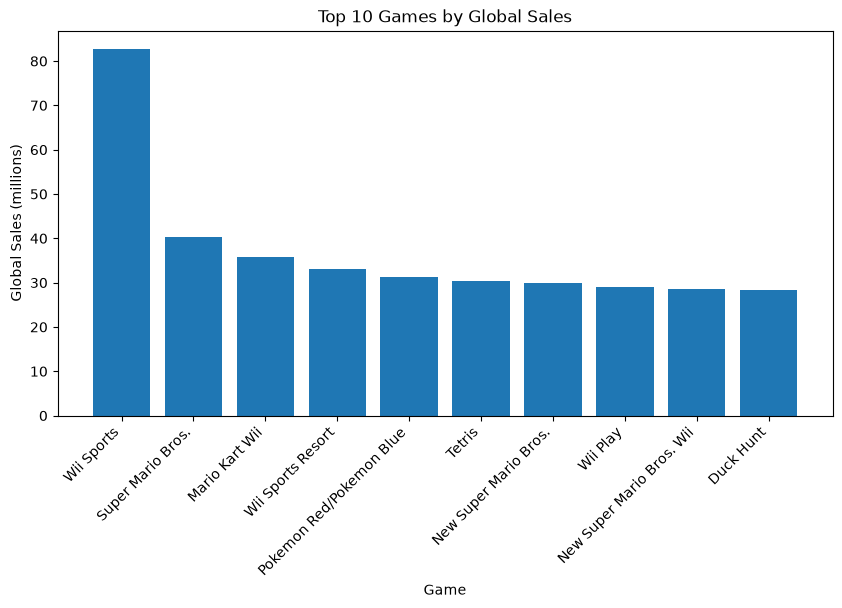

In [164]:
top10 = df.nlargest(10, "Global_Sales")
plt.figure(figsize=(10, 5))
plt.bar(top10["Name"], top10["Global_Sales"])
plt.xticks(rotation=45, ha="right")
plt.title("Top 10 Games by Global Sales")
plt.xlabel("Game")
plt.ylabel("Global Sales (millions)")
plt.show()

In [165]:
#Region-wise Sales Share

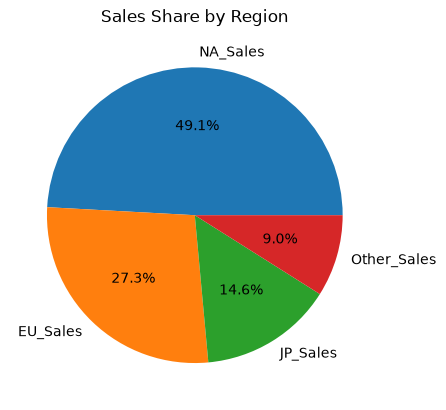

In [166]:
region = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()
plt.pie(region, labels=region.index, autopct="%1.1f%%")
plt.title("Sales Share by Region")
plt.show()

In [167]:
#Scatter Plot

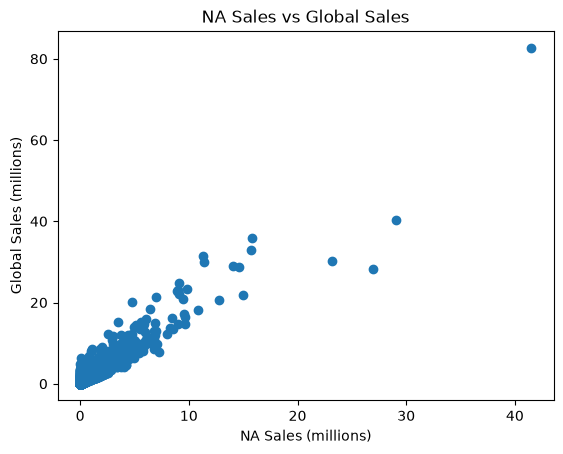

In [168]:
plt.scatter(df["NA_Sales"], df["Global_Sales"])
plt.title("NA Sales vs Global Sales")
plt.xlabel("NA Sales (millions)")
plt.ylabel("Global Sales (millions)")
plt.show()

In [169]:
#Line Chart

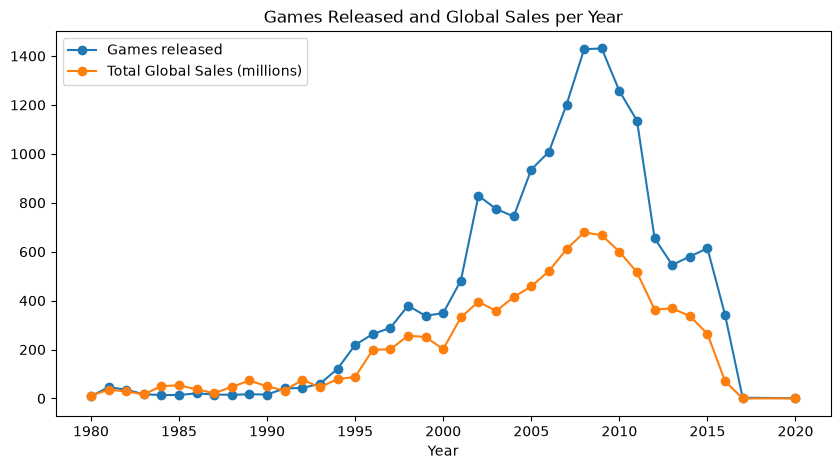

Year with most games: 2009
Year with highest sales: 2008


In [170]:
per_year = df.groupby("Year")["Global_Sales"].agg(["count", "sum"])

plt.figure(figsize=(10, 5))
plt.plot(per_year.index, per_year["count"], marker="o", label="Games released")
plt.plot(per_year.index, per_year["sum"], marker="o", label="Total Global Sales (millions)")
plt.title("Games Released and Global Sales per Year")
plt.xlabel("Year")
plt.legend()
plt.show()

print("Year with most games:", per_year["count"].idxmax())
print("Year with highest sales:", per_year["sum"].idxmax())

In [171]:
#Sampling and Distributions

In [172]:
#Compare population and samples

In [173]:
# 1. Simple Random Sampling
sample1 = df.sample(n=100, random_state=42)

# 2. Systematic Sampling
k = len(df) // 100
sample4 = df.iloc[::k]

# 3. Stratified Sampling
sample5 = df.groupby("Genre", group_keys=False).apply(lambda x: x.sample(frac=0.01, random_state=42))

# 4. Cluster Sampling
random_years = pd.Series(df["Year"].unique()).sample(n=3, random_state=42)
sample6 = df[df["Year"].isin(random_years)]

# Create the comparison table
comparison = pd.DataFrame({
    "Statistics": ["Size", "Mean", "Median", "Std Dev"],
    "Population": [len(df), df["Global_Sales"].mean(), df["Global_Sales"].median(), df["Global_Sales"].std()],
    "Simple Random": [len(sample1), sample1["Global_Sales"].mean(), sample1["Global_Sales"].median(), sample1["Global_Sales"].std()],
    "Systematic": [len(sample4), sample4["Global_Sales"].mean(), sample4["Global_Sales"].median(), sample4["Global_Sales"].std()],
    "Stratified": [len(sample5), sample5["Global_Sales"].mean(), sample5["Global_Sales"].median(), sample5["Global_Sales"].std()],
    "Cluster": [len(sample6), sample6["Global_Sales"].mean(), sample6["Global_Sales"].median(), sample6["Global_Sales"].std()]
})
comparison

C:\Users\himan\AppData\Local\Temp\ipykernel_14452\975075056.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample5 = df.groupby("Genre", group_keys=False).apply(lambda x: x.sample(frac=0.01, random_state=42))


,Statistics,Population,Simple Random,Systematic,Stratified,Cluster
0,Size,16291.000000,100.000000,101.000000,164.000000,326.000000
1,Mean,0.540910,1.013300,1.272871,0.410122,0.772117
2,Median,0.170000,0.170000,0.170000,0.165000,0.275000
3,Std Dev,1.567345,3.511048,8.226479,0.579348,2.097863


In [174]:
#Percentage error in mean

In [175]:
population_mean = df["Global_Sales"].mean()
sample_mean = sample1["Global_Sales"].mean()

error = abs((sample_mean - population_mean) / population_mean) * 100
print("Percentage Error in Mean:", error)

Percentage Error in Mean: 87.33234793127988


In [176]:
#Normal distribution

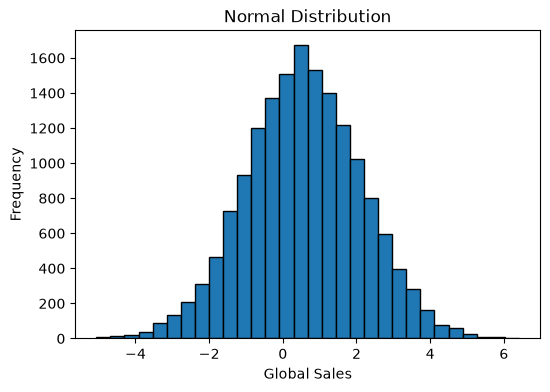

In [177]:
M = df["Global_Sales"].mean()
S = df["Global_Sales"].std()

norm = np.random.normal(M, S, len(df))

plt.figure(figsize=(6, 4))
plt.hist(norm, bins=30, edgecolor="black")
plt.title("Normal Distribution")
plt.xlabel("Global Sales")
plt.ylabel("Frequency")
plt.show()

In [178]:
#Binomial distribution

Probability of a hit game: 0.1263274200478792


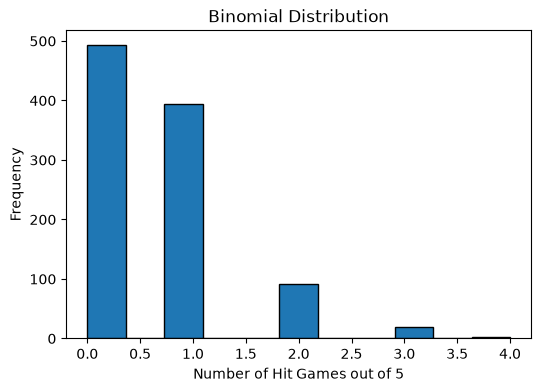

In [179]:
p = (df["Global_Sales"] >= 1).mean()
print("Probability of a hit game:", p)

binomial = np.random.binomial(n=5, p=p, size=1000)

plt.figure(figsize=(6, 4))
plt.hist(binomial, bins=11, edgecolor="black")
plt.title("Binomial Distribution")
plt.xlabel("Number of Hit Games out of 5")
plt.ylabel("Frequency")
plt.show()

In [180]:
#Poisson distribution

Lambda = 417.71794871794873


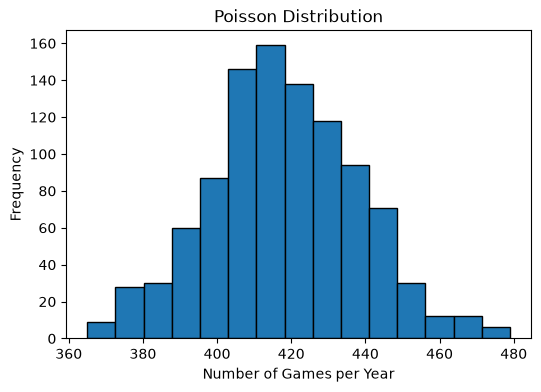

In [181]:
lambda_value = len(df) / df["Year"].nunique()
print("Lambda =", lambda_value)

poisson = np.random.poisson(lam=lambda_value, size=1000)

plt.figure(figsize=(6, 4))
plt.hist(poisson, bins=15, edgecolor="black")
plt.title("Poisson Distribution")
plt.xlabel("Number of Games per Year")
plt.ylabel("Frequency")
plt.show()

In [182]:
#Binomial probability using scipy
from scipy.stats import binom

p_hit = (df["Global_Sales"] >= 1).mean()
print("P(exactly 1 hit game out of 5) =", binom.pmf(1, 5, p_hit))
print("P(no hit game out of 5) =", binom.pmf(0, 5, p_hit))

P(exactly 1 hit game out of 5) = 0.3680124012911597
P(no hit game out of 5) = 0.5090301756634669


In [183]:
#Uniform distribution

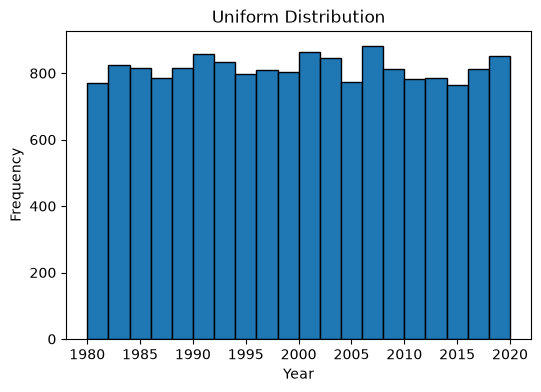

Uniform Mean Year: 2000.016841038479
Actual Mean Year: 2006.4055613528942


In [184]:
#If games were released equally in every year
uniform = np.random.uniform(df["Year"].min(), df["Year"].max(), len(df))

plt.figure(figsize=(6, 4))
plt.hist(uniform, bins=20, edgecolor="black")
plt.title("Uniform Distribution")
plt.xlabel("Year")
plt.ylabel("Frequency")
plt.show()

print("Uniform Mean Year:", uniform.mean())
print("Actual Mean Year:", df["Year"].mean())

In [185]:
#Distribution comparison: population vs samples

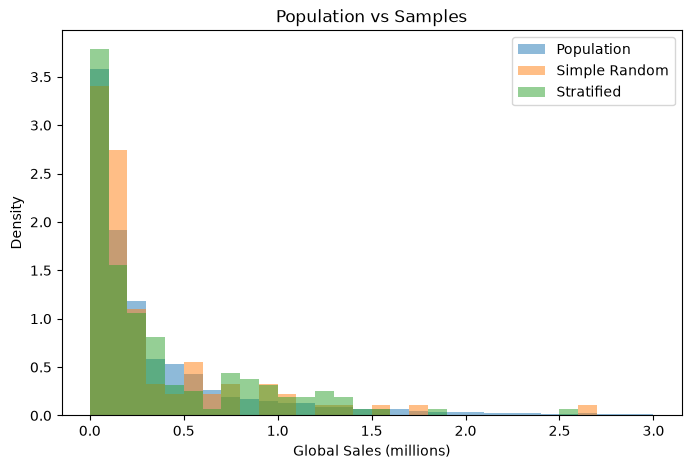

In [186]:
plt.figure(figsize=(8, 5))
plt.hist(df["Global_Sales"], bins=30, range=(0, 3), alpha=0.5, density=True, label="Population")
plt.hist(sample1["Global_Sales"], bins=30, range=(0, 3), alpha=0.5, density=True, label="Simple Random")
plt.hist(sample5["Global_Sales"], bins=30, range=(0, 3), alpha=0.5, density=True, label="Stratified")
plt.title("Population vs Samples")
plt.xlabel("Global Sales (millions)")
plt.ylabel("Density")
plt.legend()
plt.show()

In [187]:
#Probability distribution

Year
2009    0.087840
2010    0.077159
2011    0.069732
2012    0.040206
2013    0.033515
2014    0.035602
2015    0.037690
2016    0.020993
2017    0.000184
2020    0.000061
Name: proportion, dtype: float64


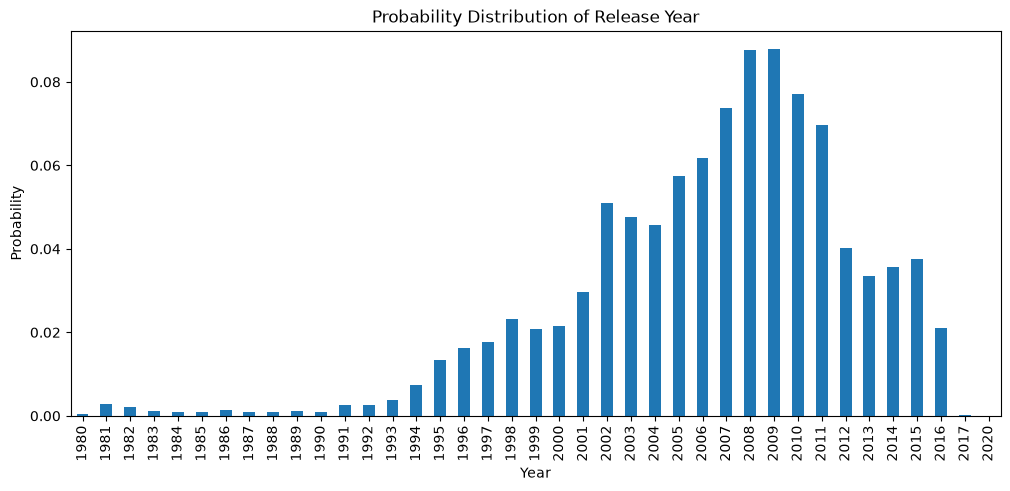

In [188]:
probability = df["Year"].value_counts(normalize=True).sort_index()
print(probability.tail(10))

probability.plot(kind="bar", figsize=(12, 5))
plt.title("Probability Distribution of Release Year")
plt.xlabel("Year")
plt.ylabel("Probability")
plt.show()

In [189]:
#Cumulative probability distribution (CDF)

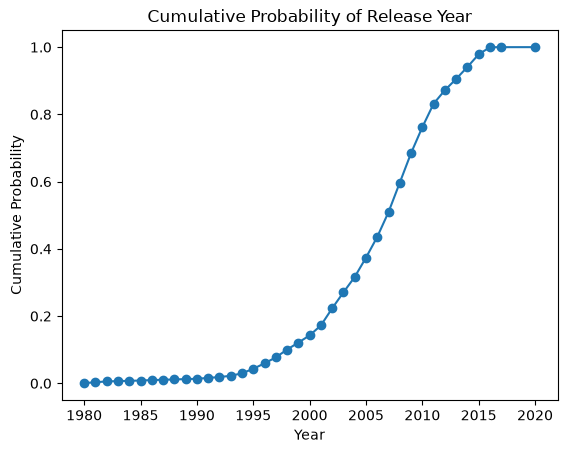

P(game released in or before 2005) = 0.3737646553311645


In [190]:
cdf = probability.cumsum()

plt.plot(cdf.index, cdf.values, marker="o")
plt.title("Cumulative Probability of Release Year")
plt.xlabel("Year")
plt.ylabel("Cumulative Probability")
plt.show()

print("P(game released in or before 2005) =", cdf[2005])

In [191]:
#Population

Population Mean: 0.5409103185808114
Population Std: 1.567296401432299


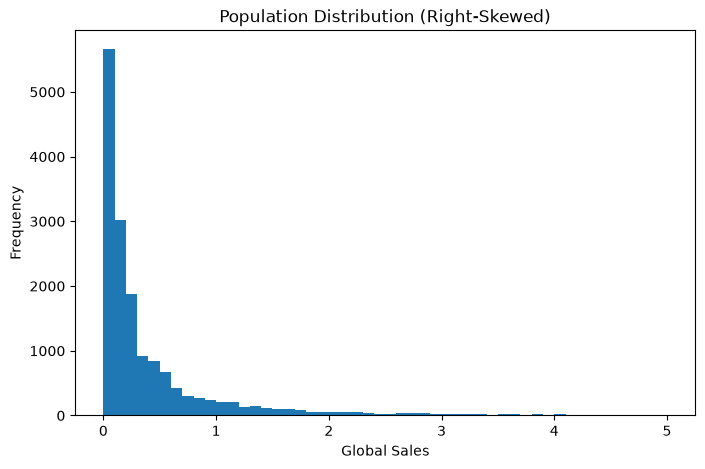

In [192]:
population = df["Global_Sales"].values
population_mean = np.mean(population)
population_std = np.std(population)

print("Population Mean:", population_mean)
print("Population Std:", population_std)

plt.figure(figsize=(8, 5))
plt.hist(population, bins=50, range=(0, 5))
plt.title("Population Distribution (Right-Skewed)")
plt.xlabel("Global Sales")
plt.ylabel("Frequency")
plt.show()

In [193]:
#Repeated sampling, n = 30

In [194]:
np.random.seed(50)
sample_size = 30
number_of_sample = 1000
sample_means = []

for i in range(number_of_sample):
    sample = np.random.choice(population, size=sample_size)
    sample_means.append(np.mean(sample))

sample_means = np.array(sample_means)

In [195]:
#Distribution of sample means

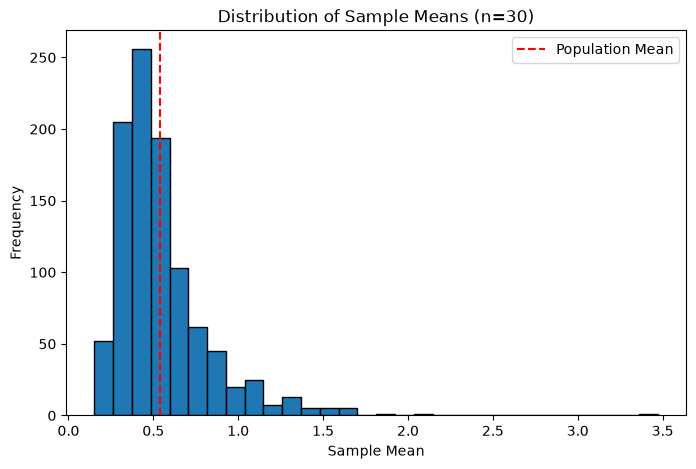

In [196]:
plt.figure(figsize=(8, 5))
plt.hist(sample_means, bins=30, edgecolor="black")
plt.axvline(population_mean, linestyle="--", color="red", label="Population Mean")
plt.title("Distribution of Sample Means (n=30)")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [197]:
#CLT results and standard error

In [198]:
observed_se = np.std(sample_means, ddof=1)
theoretical_se = population_std / np.sqrt(sample_size)

print("CLT Results")
print("Population Mean:", population_mean)
print("Mean of Sample Means:", np.mean(sample_means))
print("Observed Standard Error:", observed_se)
print("Theoretical Standard Error:", theoretical_se)

CLT Results
Population Mean: 0.5409103185808114
Mean of Sample Means: 0.5462946666666667
Observed Standard Error: 0.2778881483520845
Theoretical Standard Error: 0.2861478644537141


In [199]:
#Effect of sample size

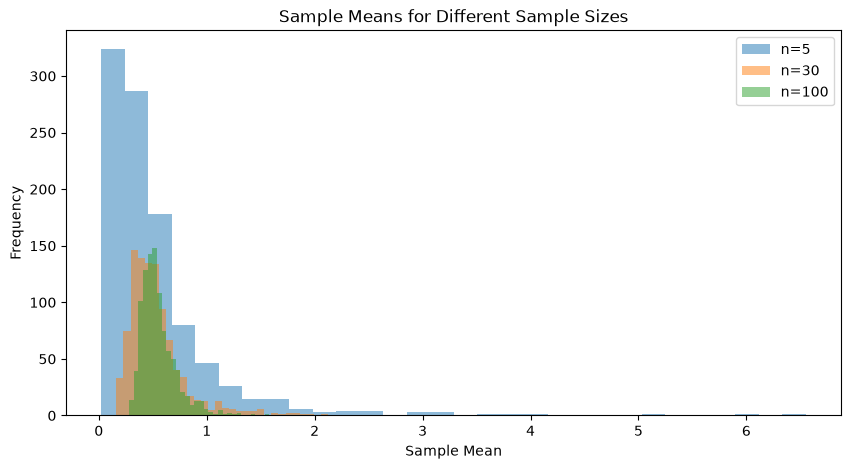

In [200]:
sizes = [5, 30, 100]
plt.figure(figsize=(10, 5))

for n in sizes:
    means = [np.mean(np.random.choice(population, size=n)) for i in range(1000)]
    plt.hist(means, bins=30, alpha=0.5, label=f"n={n}")

plt.title("Sample Means for Different Sample Sizes")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [201]:
#Point estimation

In [202]:
sample = df["Global_Sales"].sample(n=50, random_state=42)

estimated_mean = sample.mean()
estimated_variance = sample.var()
estimated_std = sample.std()

print("Point Estimation")
print("Estimated Mean:", estimated_mean)
print("Estimated Variance:", estimated_variance)
print("Estimated Standard Deviation:", estimated_std)

error = abs(estimated_mean - population_mean)
print("Estimation Error:", error)

Point Estimation
Estimated Mean: 1.4851999999999999
Estimated Variance: 23.013817306122448
Estimated Standard Deviation: 4.797271860768623
Estimation Error: 0.9442896814191885


In [203]:
#Skewness: population vs sample means

In [204]:
print("Population Skewness:", pd.Series(population).skew())
print("Sample Means Skewness (n=30):", pd.Series(sample_means).skew())

Population Skewness: 17.30431167518343
Sample Means Skewness (n=30): 2.6475839627405247


In [205]:
#Bootstrap

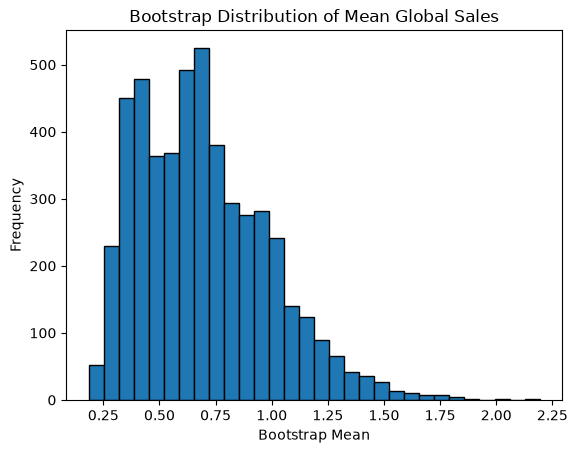

Population Mean: 0.5409103185808114
Bootstrap Estimate: 0.6968666800000001


In [206]:
#Estimate the mean from ONE sample of 50 games by resampling it 5000 times
sample = df["Global_Sales"].sample(n=50, random_state=1)
bootstrap_means = []

for i in range(5000):
    boot = sample.sample(n=50, replace=True)
    bootstrap_means.append(boot.mean())

plt.hist(bootstrap_means, bins=30, edgecolor="black")
plt.title("Bootstrap Distribution of Mean Global Sales")
plt.xlabel("Bootstrap Mean")
plt.ylabel("Frequency")
plt.show()

print("Population Mean:", population_mean)
print("Bootstrap Estimate:", np.mean(bootstrap_means))

In [207]:
#Sample mean vs sample median as estimators

In [208]:
means = []
medians = []

for i in range(1000):
    s = df["Global_Sales"].sample(n=30, replace=True)
    means.append(s.mean())
    medians.append(s.median())

print("Population Mean:", df["Global_Sales"].mean(), "| Average Sample Mean:", np.mean(means))
print("Population Median:", df["Global_Sales"].median(), "| Average Sample Median:", np.mean(medians))
print("Variance of Mean Estimator:", np.var(means, ddof=1))
print("Variance of Median Estimator:", np.var(medians, ddof=1))

Population Mean: 0.5409103185808114 | Average Sample Mean: 0.5474166666666667
Population Median: 0.17 | Average Sample Median: 0.181935
Variance of Mean Estimator: 0.07134079184740297
Variance of Median Estimator: 0.003934465240240241


In [209]:
#Confidence Interval

In [210]:
data = df["Global_Sales"]
n = len(data)
sample_mean = data.mean()
sample_std = data.std()

confidence = 0.95
standard_error = sample_std / np.sqrt(n)
t_critical = stats.t.ppf((1 + confidence) / 2, df=n-1)
margin_error = t_critical * standard_error

print("Lower Limit:", sample_mean - margin_error)
print("Upper Limit:", sample_mean + margin_error)

Lower Limit: 0.5168406031917929
Upper Limit: 0.5649800339698299


In [211]:
#Confidence Interval using Z value
z_critical = stats.norm.ppf((1 + confidence) / 2)
margin_z = z_critical * standard_error

print("Z critical =", z_critical)
print("Lower Limit:", sample_mean - margin_z)
print("Upper Limit:", sample_mean + margin_z)

Z critical = 1.959963984540054
Lower Limit: 0.5168423915955457
Upper Limit: 0.5649782455660771


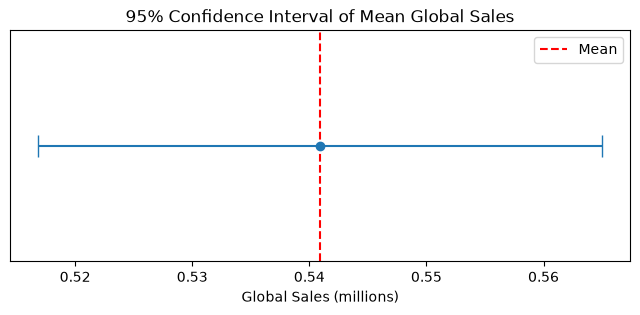

In [212]:
#Confidence Interval plot
plt.figure(figsize=(8, 3))
plt.errorbar(sample_mean, 1, xerr=margin_error, fmt="o", capsize=8)
plt.axvline(sample_mean, color="red", linestyle="--", label="Mean")
plt.yticks([])
plt.title("95% Confidence Interval of Mean Global Sales")
plt.xlabel("Global Sales (millions)")
plt.legend()
plt.show()

In [213]:
#Hypothesis Tests (t-tests)

In [214]:
#One-sample t-test

In [215]:
t, p = stats.ttest_1samp(df["Global_Sales"], 0.5)
print("Sample mean =", df["Global_Sales"].mean())
print("t-statistic =", t)
print("p-value =", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to reject H0")

Sample mean = 0.5409103185808114
t-statistic = 3.331518791108919
p-value = 0.000865655662755355
Decision: Reject H0


In [216]:
#Two-sample t-test

In [217]:
action = df[df["Genre"] == "Action"]["Global_Sales"]
sports = df[df["Genre"] == "Sports"]["Global_Sales"]

t, p = stats.ttest_ind(action, sports)
print("Action mean =", action.mean())
print("Sports mean =", sports.mean())
print("t-statistic =", t)
print("p-value =", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to reject H0")

Action mean = 0.529941556444171
Sports mean = 0.5682465277777778
t-statistic = -0.8669652615704935
p-value = 0.3859985033908565
Decision: Fail to reject H0


In [218]:
#95% Confidence Interval for difference in means (Action - Sports)
diff = action.mean() - sports.mean()
se = np.sqrt(action.var() / len(action) + sports.var() / len(sports))
dof = len(action) + len(sports) - 2

ci = stats.t.interval(0.95, dof, loc=diff, scale=se)
print("Difference in means =", diff)
print("95% CI =", ci)

Difference in means = -0.038304971333606885
95% CI = (np.float64(-0.1331503001335087), np.float64(0.056540357466294947))


In [219]:
#Paired t-test

In [220]:
t, p = stats.ttest_rel(df["NA_Sales"], df["EU_Sales"])
print("NA mean =", df["NA_Sales"].mean())
print("EU mean =", df["EU_Sales"].mean())
print("t-statistic =", t)
print("p-value =", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to reject H0")

NA mean = 0.26564667607881653
EU mean = 0.14773126266036463
t-statistic = 27.86939914163056
p-value = 5.067184380139175e-167
Decision: Reject H0


In [221]:
#Z-test

In [222]:
#H0: mean Global Sales = 0.5 million
mu = 0.5
z = (df["Global_Sales"].mean() - mu) / (df["Global_Sales"].std() / np.sqrt(len(df)))
p_z = 2 * (1 - stats.norm.cdf(abs(z)))

print("Z-statistic =", z)
print("p-value =", p_z)
print("Decision:", "Reject H0" if p_z < 0.05 else "Fail to reject H0")

Z-statistic = 3.3315187911089192
p-value = 0.0008637346850466354
Decision: Reject H0


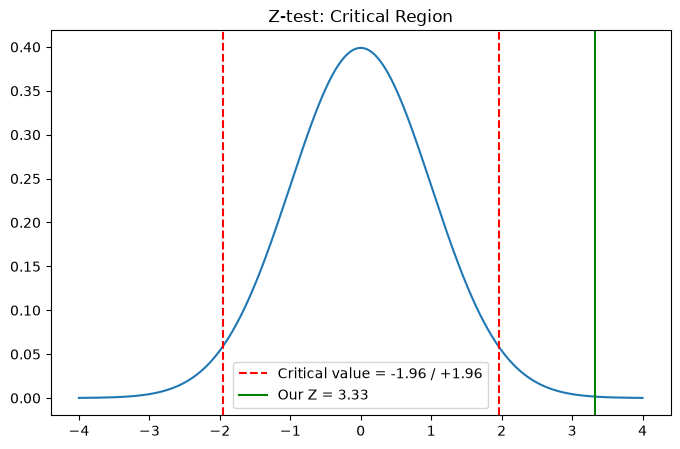

In [223]:
#Normal curve with critical values (alpha = 0.05)
x = np.linspace(-4, 4, 1000)

plt.figure(figsize=(8, 5))
plt.plot(x, stats.norm.pdf(x))
plt.axvline(-1.96, color="red", linestyle="--", label="Critical value = -1.96 / +1.96")
plt.axvline(1.96, color="red", linestyle="--")
plt.axvline(z, color="green", label="Our Z = " + str(round(z, 2)))
plt.title("Z-test: Critical Region")
plt.legend()
plt.show()

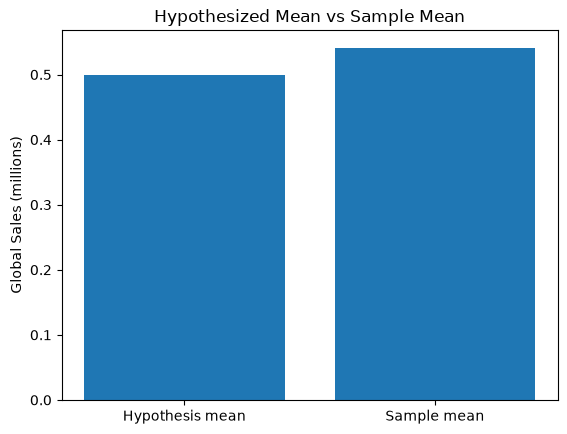

In [224]:
#Hypothesized mean vs sample mean
plt.bar(["Hypothesis mean", "Sample mean"], [mu, df["Global_Sales"].mean()])
plt.title("Hypothesized Mean vs Sample Mean")
plt.ylabel("Global Sales (millions)")
plt.show()

In [225]:
#ANOVA

In [226]:
groups = [grp["Global_Sales"].values for name, grp in df.groupby("Genre")]
F, p = stats.f_oneway(*groups)

print("F-statistic =", F)
print("p-value =", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to reject H0")

F-statistic = 18.176106122556153
p-value = 1.3358892024483616e-36
Decision: Reject H0


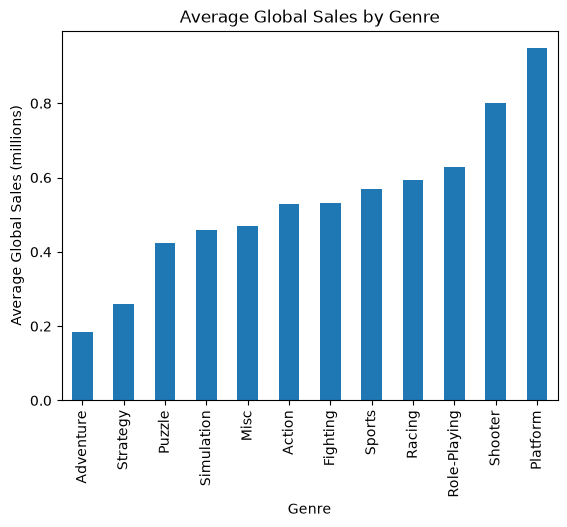

In [227]:
#Average sales by genre
df.groupby("Genre")["Global_Sales"].mean().sort_values().plot(kind="bar")
plt.title("Average Global Sales by Genre")
plt.ylabel("Average Global Sales (millions)")
plt.show()

In [228]:
#Two-way ANOVA

In [229]:
#Effect of Genre, Platform and their interaction on Global Sales
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

top5_platforms = df["Platform"].value_counts().head(5).index
top5_genres = df["Genre"].value_counts().head(5).index
data2 = df[df["Platform"].isin(top5_platforms) & df["Genre"].isin(top5_genres)]

model = ols("Global_Sales ~ C(Genre) + C(Platform) + C(Genre):C(Platform)", data=data2).fit()
anova_table = anova_lm(model, typ=2)
print(anova_table)

print("Genre significant?", anova_table["PR(>F)"]["C(Genre)"] < 0.05)
print("Platform significant?", anova_table["PR(>F)"]["C(Platform)"] < 0.05)
print("Interaction significant?", anova_table["PR(>F)"]["C(Genre):C(Platform)"] < 0.05)

                            sum_sq      df         F    PR(>F)
C(Genre)                 56.143947     4.0  3.747378  0.004763
C(Platform)             116.567763     4.0  7.780419  0.000003
C(Genre):C(Platform)    185.987528    16.0  3.103476  0.000028
Residual              19233.394795  5135.0       NaN       NaN
Genre significant? True
Platform significant? True
Interaction significant? True


In [230]:
#Chi-Square Test

In [231]:
top_platforms = df["Platform"].value_counts().head(5).index
top_genres = df["Genre"].value_counts().head(5).index
small = df[df["Platform"].isin(top_platforms) & df["Genre"].isin(top_genres)]

observed = pd.crosstab(small["Genre"], small["Platform"])
print(observed)

chi2, p, dof, expected = stats.chi2_contingency(observed)
print("Chi-Square:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to reject H0")

Platform       DS  PS2  PS3  Wii  X360
Genre                                 
Action        335  345  373  230   318
Misc          389  218  121  272   122
Role-Playing  196  183  117   35    75
Shooter        42  158  155   61   197
Sports        146  391  210  256   215
Chi-Square: 591.5379997251702
Degrees of freedom: 16
p-value: 1.4248178885745373e-115
Decision: Reject H0


In [232]:
#Expected frequencies
print(pd.DataFrame(expected, index=observed.index, columns=observed.columns).round(1))

#Degree of freedom by formula
print("DOF = (rows - 1) x (columns - 1) =", (observed.shape[0] - 1) * (observed.shape[1] - 1))

Platform         DS    PS2    PS3    Wii   X360
Genre                                          
Action        343.8  401.8  302.8  265.0  287.6
Misc          240.9  281.6  212.2  185.7  201.6
Role-Playing  130.1  152.1  114.6  100.3  108.9
Shooter       131.6  153.8  115.9  101.5  110.1
Sports        261.5  305.7  230.4  201.6  218.8
DOF = (rows - 1) x (columns - 1) = 16


In [233]:
#Chi-Square goodness of fit

In [234]:
#H0: games are equally spread across the top 5 genres
from scipy.stats import chisquare

genre_counts = df["Genre"].value_counts().head(5)
print(genre_counts)

chi2_gof, p_gof = chisquare(genre_counts)
print("Chi-Square:", chi2_gof)
print("p-value:", p_gof)
print("Decision:", "Reject H0" if p_gof < 0.05 else "Fail to reject H0")

Genre
Action          3251
Sports          2304
Misc            1686
Role-Playing    1470
Shooter         1282
Name: count, dtype: int64
Chi-Square: 1277.1075753027121
p-value: 3.0583747530234793e-275
Decision: Reject H0


In [235]:
#Correlation

In [236]:
pairs = [("NA_Sales", "Global_Sales"), ("EU_Sales", "Global_Sales"), ("JP_Sales", "Global_Sales")]

for a, b in pairs:
    x, y = df[a], df[b]
    r, p1 = stats.pearsonr(x, y)
    rho, p2 = stats.spearmanr(x, y)
    print(a, "vs", b)
    print("Covariance =", x.cov(y))
    print("Pearson r =", r, ", p =", p1)
    print("Spearman =", rho, ", p =", p2)
    print("Decision:", "Reject H0 (Significant)" if p1 < 0.05 else "Fail to reject H0")
    print()

NA_Sales vs Global_Sales
Covariance = 1.2133284689867239
Pearson r = 0.9412692156419173 , p = 0.0
Spearman = 0.7949056616713689 , p = 0.0
Decision: Reject H0 (Significant)

EU_Sales vs Global_Sales
Covariance = 0.7210331212630295
Pearson r = 0.9032637339929387 , p = 0.0
Spearman = 0.6966166845015861 , p = 0.0
Decision: Reject H0 (Significant)

JP_Sales vs Global_Sales
Covariance = 0.2995378763140712
Pearson r = 0.6127741711194435 , p = 0.0
Spearman = 0.15506548723574354 , p = 3.2676931515474467e-88
Decision: Reject H0 (Significant)



In [237]:
#Correlation heatmap

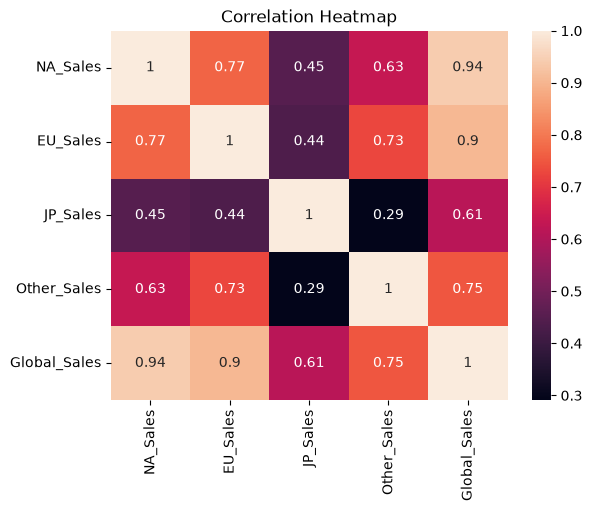

In [238]:
sns.heatmap(df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]].corr(), annot=True)
plt.title("Correlation Heatmap")
plt.show()

In [239]:
#Direction and strength
r = df["NA_Sales"].corr(df["Global_Sales"])
print("Correlation (NA vs Global) =", r)
print("Direction:", "Positive" if r > 0 else "Negative")
print("Strength:", "Strong" if abs(r) >= 0.7 else "Moderate" if abs(r) >= 0.3 else "Weak")

Correlation (NA vs Global) = 0.9412692156419169
Direction: Positive
Strength: Strong


In [240]:
#Covariance matrix
df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]].cov()

,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
NA_Sales,0.676395,0.322077,0.115754,0.099194,1.213328
EU_Sales,0.322077,0.259389,0.069315,0.070309,0.721033
JP_Sales,0.115754,0.069315,0.097269,0.017225,0.299538
Other_Sales,0.099194,0.070309,0.017225,0.036131,0.222837
Global_Sales,1.213328,0.721033,0.299538,0.222837,2.456569


In [241]:
#PR7 - PART A: REGRESSION (Predict Global Sales from NA Sales)

In [242]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [243]:
X = df[["NA_Sales"]]      #Independent variable
Y = df["Global_Sales"]    #Dependent variable

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print("Training Sample:", len(X_train))
print("Testing Sample:", len(X_test))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Training Sample: 13032
Testing Sample: 3259


In [244]:
#Train all 5 models and compare
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
}

results = []
for name, m in models.items():
    m.fit(X_train, Y_train)
    pred = m.predict(X_test)
    mae = mean_absolute_error(Y_test, pred)
    mse = mean_squared_error(Y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(Y_test, pred)
    results.append([name, mae, mse, rmse, r2])

results_df = pd.DataFrame(results, columns=["Model", "MAE", "MSE", "RMSE", "R2"])
results_df = results_df.sort_values(by="R2", ascending=False)
results_df

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,0.209798,0.338439,0.581755,0.920888
1,Ridge Regression,0.209805,0.338489,0.581798,0.920876
2,Lasso Regression,0.220954,0.406735,0.637758,0.904923
3,Decision Tree,0.222789,0.885035,0.940763,0.793118
4,Random Forest,0.216458,0.971135,0.985462,0.772992


In [245]:
#Linear regression equation
lin = models["Linear Regression"]
print("Intercept:", lin.intercept_)
print("Slope:", lin.coef_[0])
print("Equation: Global Sales =", round(lin.intercept_, 2), "+", round(lin.coef_[0], 2), "* NA Sales (scaled)")

Intercept: 0.5340323818293431
Slope: 1.3162874892064294
Equation: Global Sales = 0.53 + 1.32 * NA Sales (scaled)


In [246]:
#Actual vs predicted (first 5 test games)
prediction_df = pd.DataFrame({"Actual": Y_test.values[:5]})
for name, m in models.items():
    prediction_df[name] = m.predict(X_test[:5]).round(2)
prediction_df

,Actual,Linear Regression,Ridge Regression,Lasso Regression,Decision Tree,Random Forest
0,0.57,0.98,0.98,0.95,0.96,0.97
1,0.07,0.08,0.08,0.11,0.12,0.12
2,0.19,0.08,0.08,0.11,0.12,0.12
3,0.67,0.84,0.84,0.82,0.72,0.76
4,0.22,0.36,0.36,0.37,0.36,0.33


In [247]:
#Best model
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]
print("Best Model:", best_model_name)

Best Model: Linear Regression


In [248]:
#Save and load the model
import joblib
joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")

model = joblib.load("best_model.pkl")
scaler = joblib.load("scaler.pkl")

In [249]:
#PR7 - PART B: CLASSIFICATION (Will the game be a HIT?)

Hit
0    14233
1     2058
Name: count, dtype: int64


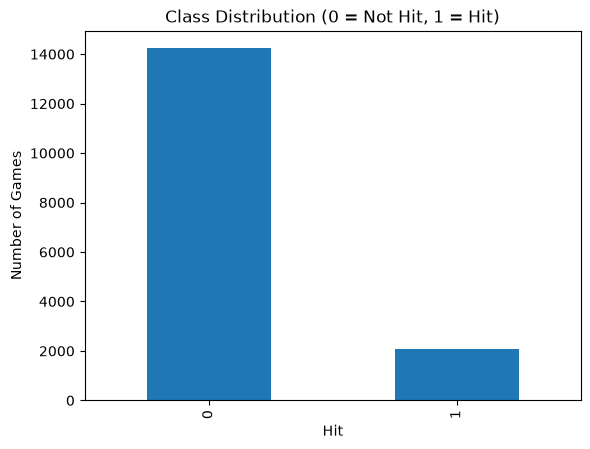

In [250]:
#Target: Hit = 1 if Global Sales >= 1 million, else 0
df["Hit"] = (df["Global_Sales"] >= 1).astype(int)
print(df["Hit"].value_counts())

df["Hit"].value_counts().plot(kind="bar")
plt.title("Class Distribution (0 = Not Hit, 1 = Hit)")
plt.xlabel("Hit")
plt.ylabel("Number of Games")
plt.show()

In [251]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [252]:
Xc = df[["NA_Sales"]]     #Input feature
yc = df["Hit"]            #Target (0 or 1)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)
print("Training Sample:", len(Xc_train))
print("Testing Sample:", len(Xc_test))

scaler_c = StandardScaler()
Xc_train = scaler_c.fit_transform(Xc_train)
Xc_test = scaler_c.transform(Xc_test)

Training Sample: 13032
Testing Sample: 3259


In [253]:
#Train 4 classification models and compare
classifiers = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
}

c_results = []
for name, c in classifiers.items():
    c.fit(Xc_train, yc_train)
    pred = c.predict(Xc_test)
    c_results.append([name,
                      accuracy_score(yc_test, pred),
                      precision_score(yc_test, pred),
                      recall_score(yc_test, pred),
                      f1_score(yc_test, pred)])

c_results_df = pd.DataFrame(c_results, columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score"])
c_results_df = c_results_df.sort_values(by="F1-Score", ascending=False)
c_results_df

,Model,Accuracy,Precision,Recall,F1-Score
2,Decision Tree,0.957963,0.887324,0.764563,0.821382
3,Random Forest,0.957349,0.880223,0.766990,0.819715
0,Logistic Regression,0.958269,0.915663,0.737864,0.817204
1,KNN,0.951519,0.830729,0.774272,0.801508


Best Classification Model: Decision Tree
[[2807   40]
 [  97  315]]


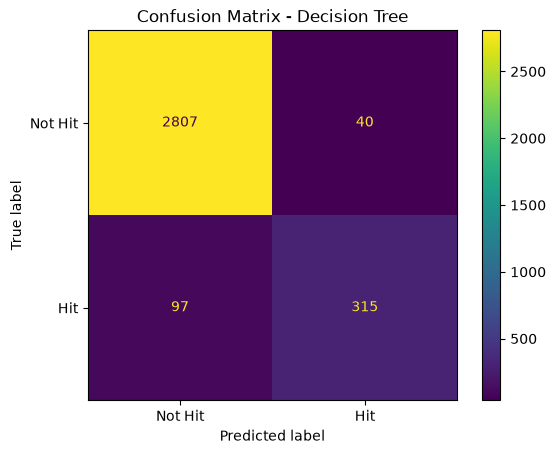

In [254]:
#Best classification model (chosen by F1-Score)
best_clf_name = c_results_df.iloc[0]["Model"]
best_clf = classifiers[best_clf_name]
print("Best Classification Model:", best_clf_name)

cm = confusion_matrix(yc_test, best_clf.predict(Xc_test))
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["Not Hit", "Hit"]).plot()
plt.title("Confusion Matrix - " + best_clf_name)
plt.show()

In [255]:
#Save and load the classification model
joblib.dump(best_clf, "best_classifier.pkl")
joblib.dump(scaler_c, "scaler_classifier.pkl")

clf = joblib.load("best_classifier.pkl")
scaler_c = joblib.load("scaler_classifier.pkl")

In [256]:
def predict_game(na_sales):
    x = pd.DataFrame({"NA_Sales": [na_sales]})
    sales = model.predict(scaler.transform(x))[0]
    hit = clf.predict(scaler_c.transform(x))[0]
    result = "Predicted Global Sales: " + str(round(sales, 2)) + " million copies\n"
    result = result + "Prediction: " + ("HIT game" if hit == 1 else "NOT a hit")
    return result

print(predict_game(1.0))     #test: a game that sold 1 million copies in North America
print(predict_game(0.2))

Predicted Global Sales: 1.82 million copies
Prediction: HIT game
Predicted Global Sales: 0.43 million copies
Prediction: NOT a hit


In [257]:
#PR7 - GUI: Gradio app (public link)

In [258]:
!pip install -q gradio


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\himan\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [265]:
import gradio as gr

def predict_game(na_sales):
    x = pd.DataFrame({"NA_Sales": [na_sales]})
    sales = round(float(model.predict(scaler.transform(x))[0]), 2)
    prob = clf.predict_proba(scaler_c.transform(x))[0]
    hit = {"HIT game": float(prob[1]), "Not a hit": float(prob[0])}
    beaten = round((df["Global_Sales"] < sales).mean() * 100, 1)
    summary = (f"A game that sells {na_sales} million copies in North America is expected to sell "
               f"about {sales} million copies worldwide. That is more than {beaten}% of all games in the dataset.")
    chart = pd.DataFrame({"Region": ["North America", "Worldwide (predicted)"],
                          "Sales (millions)": [na_sales, sales]})
    return sales, hit, summary, chart

In [264]:
with gr.Blocks() as interface:
    gr.Markdown("# 🎮 Video Game Sales and Hit Predictor")
    with gr.Row():
        with gr.Column():
            na_input = gr.Slider(0, 10, value=1, step=0.1, label="NA Sales (millions)")
            with gr.Row():
                clear_btn = gr.Button("Clear")
                predict_btn = gr.Button("Predict", variant="primary")
            chart_out = gr.BarPlot(x="Region", y="Sales (millions)", y_lim=[0, None], title="NA Sales vs Predicted Global Sales")
        with gr.Column():
            sales_out = gr.Number(label="Predicted Global Sales (millions)")
            hit_out = gr.Label(label="Hit or Not Hit")
            summary_out = gr.Textbox(label="Summary", lines=3)
    gr.Markdown("Models used: Linear Regression for global sales (R2 = 0.92) and Decision Tree for hit prediction (accuracy 95.8%).")

    predict_btn.click(predict_game, inputs=na_input, outputs=[sales_out, hit_out, summary_out, chart_out])
    clear_btn.click(lambda: (1, None, None, "", None), outputs=[na_input, sales_out, hit_out, summary_out, chart_out])

interface.launch(share=True, theme=gr.themes.Soft())

* Running on local URL:  http://127.0.0.1:7870
* Running on public URL: https://efc236e98d8ccff0b5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**CONCLUSION**

Video game sales are highly right skewed: most games sell less than 0.5 million copies and a few hits sell a lot.
North America is the biggest market and has the strongest relation with global sales (r = 0.94).
Sampling and the CLT work well: sample means are close to the population mean and become normal even though the data is skewed.
Genre and platform both have a significant effect on sales, and they are related to each other.
For regression, Linear Regression predicts global sales from NA sales with R2 = 0.92.
For classification, Decision Tree predicts whether a game will be a hit with 95.8% accuracy and an F1-Score of 0.82.
Both best models are saved with joblib and used in a Gradio app with a public link.